# Experiment D — 固定Cue候補からの24文選定とdY統制

**CPU / 文章生成API 0回 / GPU不要。** Bの75新規ペア＋5旧Yアンカー（別集計）、700既存Cueを使用。距離帯はBが継承したv3 setting C（最大±0.04、帯間隔0.03以上）に固定。関連5帯×4タイプ＋無関係4タイプ＝24スロット。候補が不足しても境界・品質基準を緩和しない。

- 同一候補集合から、距離帯中心を優先したY非考慮ベースラインと、dY相関・帯平均差のjoint最適化を比較。
- 主分析: 旧品質通過・新Yの名称/別名露出なし。感度分析: Bの部分意味監査で既知不適格のCueも除外。未監査Cueを合格とはみなさない。
- 最大採択数はMILPで厳密に計算（成功時）、jointは固定3 seed×1200 stepの近似探索。失敗は不可能の証明ではない。結果はPROVISIONAL。
- Cの25ペアのProbe成績は選定完了後だけ結合。正式採択なし。距離閾値は探索的。
- Colab Secrets: GITHUB_RESULTS_TOKEN のみ。GitHubへX単位の圧縮チェックポイント5件＋集計結果。別run IDで再実験。OpenAI APIキー・Drive不要。


In [1]:
import io,json,time,base64,hashlib,itertools,unicodedata,platform,zipfile
from pathlib import Path
from difflib import SequenceMatcher
import importlib.metadata as im
import numpy as np,pandas as pd,requests,matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.stats import rankdata,spearmanr
from google.colab import userdata
from IPython.display import display
from tqdm.auto import tqdm
CFG=json.loads("{\"repo\":\"ryouy/GraduationThesis\",\"branch\":\"experiments/concept-pair-selection-v1\",\"run_id\":\"20261126_concept_pair_distance_D_v1\",\"B_ref\":\"ada2278f06f89a9adc32c4efe2eab083935cfd68\",\"C_ref\":\"6eb730f8dcaf48bfce9d98825b13e41d2a4dbd25\",\"B_root\":\"experiments/2026-11/1126_concept_pair_selection/results/20261126_concept_pair_distance_B_v1/\",\"C_root\":\"experiments/2026-11/1126_concept_pair_selection/results/20261126_concept_pair_distance_C_small_v1/\",\"setting\":\"C\",\"half_width\":0.04,\"min_gap\":0.03,\"styles\":[\"structure\",\"action\",\"situation\",\"function\"],\"seeds\":[11,23,37],\"steps_per_seed\":1200,\"rho_target\":0.3,\"spread_target\":0.05,\"duplicate_threshold\":0.8,\"pools\":[\"old_quality_no_y_name\",\"known_audit_fail_excluded\"],\"primary_pool\":\"old_quality_no_y_name\",\"include_anchors\":true,\"api_calls\":0,\"status\":\"exploratory\"}")
REPO=CFG['repo'];BRANCH=CFG['branch']
DEST='experiments/2026-11/1126_concept_pair_selection/results/'+CFG['run_id']+'/'
BASE='https://api.github.com/repos/'+REPO+'/contents/'
WORK=Path('/content')/CFG['run_id'];WORK.mkdir(exist_ok=True)
TOKEN=userdata.get('GITHUB_RESULTS_TOKEN')
assert TOKEN,'Set Colab Secret GITHUB_RESULTS_TOKEN'
gh=requests.Session();gh.headers.update({'Authorization':'Bearer '+TOKEN,'Accept':'application/vnd.github+json'})
def dump(x):return (json.dumps(x,ensure_ascii=False,sort_keys=True,indent=2,allow_nan=False)+'\n').encode()
def sha(b):return hashlib.sha256(b).hexdigest()
def blob(b):return hashlib.sha1(b'blob '+str(len(b)).encode()+b'\0'+b).hexdigest()
def norm(s):return ' '.join(unicodedata.normalize('NFKC',str(s)).casefold().split())
def boolean(s):
    v=s.astype(str).str.lower();assert v.isin(['true','false']).all()
    return v.eq('true')
def wait_for(r,i):
    wait=max(2**i,2)
    if r.headers.get('Retry-After','').isdigit():wait=max(wait,int(r.headers['Retry-After']))
    if r.headers.get('X-RateLimit-Remaining')=='0' and r.headers.get('X-RateLimit-Reset','').isdigit():wait=max(wait,int(r.headers['X-RateLimit-Reset'])-int(time.time())+3)
    if r.status_code in (403,429):wait=max(wait,60)
    time.sleep(wait)
def read(path,ref=BRANCH):
    for i in range(6):
        try:
            r=gh.get(BASE+path,params={'ref':ref},timeout=120)
            if r.status_code==404:return None
            if r.status_code in (429,500,502,503,504) or (r.status_code==403 and 'rate limit' in r.text.lower()):
                wait_for(r,i);continue
            r.raise_for_status();j=r.json()
            if j.get('encoding')=='base64':b=base64.b64decode(j['content'])
            else:
                r=gh.get(BASE+path,params={'ref':ref},headers={'Accept':'application/vnd.github.raw+json'},timeout=120)
                if r.status_code in (429,500,502,503,504) or (r.status_code==403 and 'rate limit' in r.text.lower()):
                    wait_for(r,i);continue
                r.raise_for_status();b=r.content
            assert blob(b)==j['sha'],'Git blob mismatch '+path
            return b
        except (requests.ConnectionError,requests.Timeout):time.sleep(min(60,2**i))
    raise RuntimeError('GitHub read retries exhausted: '+path)
def get(n):return read(DEST+n)
def put(n,b):
    for i in range(6):
        old=get(n)
        if old is not None:
            if old!=b:raise RuntimeError('Immutable conflict: '+n+'; use a new run_id')
            break
        try:
            r=gh.put(BASE+DEST+n,json={'branch':BRANCH,'message':'Experiment D: '+n,'content':base64.b64encode(b).decode()},timeout=120)
            if r.ok:time.sleep(1.2);break
            if r.status_code not in (409,422,429,500,502,503,504) and not (r.status_code==403 and 'rate limit' in r.text.lower()):r.raise_for_status()
            wait_for(r,i)
        except (requests.ConnectionError,requests.Timeout):time.sleep(min(60,2**i))
    else:raise RuntimeError('GitHub write retries exhausted: '+n)
    p=WORK/n;p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(b)
def save_df(n,g):put(n,g.to_csv(index=False,lineterminator='\n').encode())
if get('manifest.json') is not None:raise RuntimeError('Run already complete. Read results, or change run_id.')
print('Run',CFG['run_id'])


Run 20261126_concept_pair_distance_D_v1


In [2]:
# Load B output and freeze its inputs. No embedding inference or API generation.
bfiles=['manifest.json','config.json','candidate_pairs.csv','cue_distances_all_eligible.csv','cue_semantic_audit.csv','cue_structural_feasibility.csv']
raw={n:read(CFG['B_root']+n,CFG['B_ref']) for n in bfiles}
assert all(raw.values())
bm=json.loads(raw['manifest.json']);bc=json.loads(raw['config.json'])
assert bm['status']=='complete_exploratory' and bm['n_primary']==75 and bm['n_anchors']==5
for n in bfiles[1:]:assert sha(raw[n])==bm['files'][n],n
assert bc['setting']==CFG['setting']
bounds_raw=read(bc['source_paths']['bounds'],bc['source_ref'])
assert sha(bounds_raw)==bc['input_sha256']['bounds']
bounds=pd.read_csv(io.BytesIO(bounds_raw))
bounds=bounds[(bounds.setting==CFG['setting'])&(~boolean(bounds.y_control))].copy()
assert len(bounds)==25
for pid,g in bounds.groupby('pair'):
    g=g.sort_values('band');assert g.band.tolist()==list(range(5))
    assert np.all(g.lo.to_numpy()[1:]-g.hi.to_numpy()[:-1]>=CFG['min_gap']-1e-6)
    assert np.all(g.center-g.lo<=CFG['half_width']+1e-6) and np.all(g.hi-g.center<=CFG['half_width']+1e-6)
cand=pd.read_csv(io.BytesIO(raw['candidate_pairs.csv']))
for k in ['primary_selected','original_y','same_category','eligible']:cand[k]=boolean(cand[k])
pairs=cand[cand.primary_selected|(cand.original_y&CFG['include_anchors'])].sort_values(['pair','original_y','candidate_id']).copy()
assert len(pairs)==80 and pairs.primary_selected.sum()==75 and pairs.eligible.all()
assert pairs[pairs.primary_selected].groupby(['pair','distance_band']).size().eq(3).all()
m=pd.read_csv(io.BytesIO(raw['cue_distances_all_eligible.csv']))
m=m[m.candidate_id.isin(pairs.candidate_id)].copy()
for k in ['quality_pass','y_name_exposed']:m[k]=boolean(m[k])
assert not m.duplicated(['candidate_id','id']).any() and m.groupby('candidate_id').size().eq(140).all()
assert m.id.nunique()==700 and m[m.quality_pass].id.nunique()==622
assert np.isfinite(m[['d_x','d_y']]).all().all()
assert m.fixed_band.isin(range(-1,6)).all()
# Verify dX and fixed band assignment per candidate against B's pinned bounds.
for pid,g in m.groupby('pair'):
    ref=g.drop_duplicates('id').set_index('id')
    for _,h in g.groupby('candidate_id'):
        q=h.set_index('id').loc[ref.index]
        assert np.allclose(q.d_x,ref.d_x,rtol=0,atol=1e-9)
        assert np.array_equal(q.fixed_band,ref.fixed_band)
    expected=np.full(len(ref),-1)
    for z in bounds[bounds.pair==pid].itertuples():
        expected[(ref.related==1)&ref.d_x.between(z.lo,z.hi)]=z.band
    expected[ref.related==0]=5
    assert np.array_equal(expected,ref.fixed_band)
sem=pd.read_csv(io.BytesIO(raw['cue_semantic_audit.csv']))
assert len(sem)==960 and not sem.duplicated(['candidate_id','id']).any()
m=m.merge(sem[['candidate_id','id','x_related','y_related','exposure','y_specific']],on=['candidate_id','id'],how='left',validate='one_to_one')
m['audited_new_y']=m.exposure.notna()
m['known_audit_pass']=m.audited_new_y&(m.exposure=='pass')&(m.y_specific=='no')&(~m.y_name_exposed)&(((m.related==1)&(m.x_related>=1))|((m.related==0)&(m.x_related==0)&(m.y_related==0)))
m['known_audit_fail']=m.audited_new_y&~m.known_audit_pass
old_feas=pd.read_csv(io.BytesIO(raw['cue_structural_feasibility.csv']))
old_feas=old_feas[old_feas.subset==CFG['primary_pool']].set_index('candidate_id')
assert len(old_feas)==80
config={**CFG,'input_sha256':{**{k:sha(v) for k,v in raw.items()},'bounds.csv':sha(bounds_raw)},'objective':'baseline: maximum cardinality, then minimum sum |dX-center|; joint: maximize cardinality, prioritize all 5 related bands, then prefer meeting both diagnostic targets, then max(|rho|/.30,spread/.05)+.1*(|rho|/.30+spread/.05) + 1e-5 mean center error; no suppression data','semantic_audit_rule':'B partial audit only; known failure or uncertain excluded in sensitivity; unreviewed kept and labeled','checkpoint_format':'one zip per X, deterministic fixed archive timestamp'}
put('config.json',dump(config))
save_df('selected_pairs.csv',pairs[['pair','candidate_id','x','concept','distance_xy','distance_band','same_category','token_diff','primary_selected','original_y']].rename(columns={'concept':'y'}))
print('B primary:',int(pairs.primary_selected.sum()),'anchors:',int(pairs.original_y.sum()),'cue rows:',len(m),'old pass unique:',m[m.quality_pass].id.nunique())


B primary: 75 anchors: 5 cue rows: 11200 old pass unique: 622


In [3]:
# Build exact maximum-cardinality baseline and seeded joint search.
SLOTS=list(itertools.product(range(6),CFG['styles']))
CONFLICT={}
for pid,g in m.groupby('pair'):
    q=g.drop_duplicates('id').sort_values('id')
    rows=list(q[['id','cue']].itertuples(index=False,name=None))
    CONFLICT[pid]={(a,c) for (a,b),(c,d) in itertools.combinations(rows,2) if SequenceMatcher(None,norm(b),norm(d)).ratio()>=CFG['duplicate_threshold']}
def prepare(q,centers):
    g=q[q.fixed_band>=0].sort_values('id').reset_index(drop=True)
    slots=[np.flatnonzero((g.fixed_band==b)&(g['style']==s)) for b,s in SLOTS]
    n=len(g);c=np.zeros((n,n),dtype=bool)
    ids={v:i for i,v in enumerate(g.id)}
    for a,b in CONFLICT[q.pair.iloc[0]] if len(q) else []:
        if a in ids and b in ids:c[ids[a],ids[b]]=c[ids[b],ids[a]]=True
    A=[]
    for v in slots:
        row=np.zeros(n);row[v]=1;A.append(row)
    for i,j in zip(*np.where(np.triu(c,1))):
        row=np.zeros(n);row[[i,j]]=1;A.append(row)
    band=g.fixed_band.to_numpy(dtype=int);dx=g.d_x.to_numpy(float);dy=g.d_y.to_numpy(float)
    err=np.zeros(n);rel=band<5;err[rel]=abs(dx[rel]-centers[band[rel]])
    initial=np.full(24,-1,dtype=int)
    if n:
        A=np.array(A);cons=LinearConstraint(A,0,1)
        res=milp(-np.ones(n),integrality=np.ones(n),bounds=Bounds(0,1),constraints=cons,options={'time_limit':60,'mip_rel_gap':0})
        if not res.success:raise RuntimeError('Exact cardinality solver failed: '+str(res.message))
        maximum=int(np.rint(res.x).sum())
        # Min center error without using dY; small ID-order tie break.
        res2=milp(err+1e-9*np.arange(n),integrality=np.ones(n),bounds=Bounds(0,1),constraints=[cons,LinearConstraint(np.ones((1,n)),maximum,maximum)],options={'time_limit':60,'mip_rel_gap':0})
        if not res2.success:raise RuntimeError('Baseline solver failed: '+str(res2.message))
        chosen=set(np.flatnonzero(np.rint(res2.x)))
        for i,pool in enumerate(slots):
            z=chosen.intersection(pool)
            assert len(z)<=1
            if z:initial[i]=next(iter(z))
    else:maximum=0
    assert (initial>=0).sum()==maximum
    return g,slots,c,band,dx,dy,err,initial,maximum
def diagnostics(state,band,dx,dy,err):
    idx=state[state>=0];idx=idx[band[idx]<5]
    counts=np.bincount(band[idx],minlength=5)
    coverage=int(np.count_nonzero(counts))
    rho=np.nan;spread=np.nan
    if len(idx)>=3:
        a=rankdata(dx[idx]);b=rankdata(dy[idx]);a-=a.mean();b-=b.mean()
        den=np.sqrt((a@a)*(b@b))
        if den>0:rho=float(np.clip(a@b/den,-1,1))
    if coverage==5:
        means=np.bincount(band[idx],weights=dy[idx],minlength=5)/counts
        spread=float(means.max()-means.min())
    return rho,spread,float(dy[idx].std(ddof=0)) if len(idx) else np.nan,coverage,float(err[idx].mean()) if len(idx) else np.nan
def quality_score(state,band,dx,dy,err):
    rho,spread,_,coverage,center=diagnostics(state,band,dx,dy,err)
    if coverage<5:return 1000.+100*(5-coverage)
    if not np.isfinite(rho) or not np.isfinite(spread):return 900.
    a=abs(rho)/CFG['rho_target'];b=spread/CFG['spread_target']
    return max(a,b)+.1*(a+b)+1e-5*center
def passed(rho,spread):
    return bool(np.isfinite(rho) and np.isfinite(spread) and abs(rho)<=CFG['rho_target'] and spread<=CFG['spread_target'])
def validate(state,g,pools,c,maximum):
    idx=state[state>=0]
    assert len(idx)==maximum and len(set(idx))==maximum
    assert not c[np.ix_(idx,idx)].any()
    for j,k in enumerate(state):
        if k>=0:assert k in pools[j]
    if len(idx):assert g.iloc[idx].id.is_unique and g.iloc[idx].quality_pass.all() and not g.iloc[idx].y_name_exposed.any()
def optimize(initial,pools,c,band,dx,dy,err,seed):
    rng=np.random.default_rng(seed)
    cur=initial.copy();cur_score=quality_score(cur,band,dx,dy,err)
    best=cur.copy();best_score=cur_score
    rho,spread,*_=diagnostics(cur,band,dx,dy,err)
    best_pass=cur.copy() if passed(rho,spread) else None;best_pass_score=cur_score if best_pass is not None else np.inf
    steps=CFG['steps_per_seed']
    if not (cur>=0).any():return best,best_score,False
    for step in range(steps):
        prop=cur.copy();filled=np.flatnonzero(cur>=0);empty=np.flatnonzero(cur<0)
        if len(empty) and rng.random()<.2:
            source=int(rng.choice(filled));dest=int(rng.choice(empty))
            if not len(pools[dest]):continue
            prop[source]=-1
        else:dest=int(rng.choice(filled))
        if not len(pools[dest]):continue
        candidate=int(rng.choice(pools[dest]))
        if prop[dest]==candidate:continue
        prop[dest]=candidate;idx=prop[prop>=0]
        if c[np.ix_(idx,idx)].any():continue
        val=quality_score(prop,band,dx,dy,err)
        if val<best_score-1e-12:best=prop.copy();best_score=val
        if val<best_pass_score and val<=1.20002:
            rho,spread,*_=diagnostics(prop,band,dx,dy,err)
            if passed(rho,spread):best_pass=prop.copy();best_pass_score=val
        temp=.5*(.002/.5)**(step/max(steps-1,1))
        if val<=cur_score or rng.random()<np.exp(min(0.,(cur_score-val)/temp)):
            cur=prop;cur_score=val
    if best_pass is not None:return best_pass,best_pass_score,True
    return best,best_score,False
print('Optimizer ready; maximum cardinality is exact, joint objective is heuristic.')


Optimizer ready; maximum cardinality is exact, joint objective is heuristic.


In [4]:
# Small self-test before processing research data.
# One complete, no-duplicate synthetic set with constant dY -> undefined correlation is NOT a pass.
test=pd.DataFrame([{'id':f't{i}','pair':'test','cue':f'unique {i}','fixed_band':b,'style':s,'d_x':.1+b*.1,'d_y':.8,'quality_pass':True,'y_name_exposed':False} for i,(b,s) in enumerate(SLOTS)])
CONFLICT['test']=set()
g,pools,c,band,dx,dy,err,initial,maximum=prepare(test,np.arange(5)*.1+.1)
validate(initial,g,pools,c,maximum)
assert maximum==24
rho,spread,sd,coverage,center=diagnostics(initial,band,dx,dy,err)
assert np.isnan(rho) and not passed(rho,spread) and coverage==5
# Remove one slot and add conflict between two distinct slots.
CONFLICT['test']={('t0','t1')}
g,pools,c,band,dx,dy,err,initial,maximum=prepare(test.iloc[:-1],np.arange(5)*.1+.1)
assert maximum==22
validate(initial,g,pools,c,maximum)
st,_,_=optimize(initial,pools,c,band,dx,dy,err,11)
validate(st,g,pools,c,maximum)
del CONFLICT['test']
print('Self-tests passed.')


Self-tests passed.


In [5]:
# Run one family at a time and save one deterministic ZIP checkpoint.
# Comparison is paired: same pool, same exact maximum n, same constraints.
tables=['summary.csv','selected.csv','search_runs.csv','missing_slots.csv','slot_inventory.csv']
def pack(items):
    buf=io.BytesIO()
    with zipfile.ZipFile(buf,'w',compression=zipfile.ZIP_DEFLATED) as z:
        z.writestr(zipfile.ZipInfo('config_sha256.txt',date_time=(2026,1,1,0,0,0)),sha(dump(config)))
        for n,g in items.items():
            z.writestr(zipfile.ZipInfo(n,date_time=(2026,1,1,0,0,0)),g.to_csv(index=False,lineterminator='\n').encode(),compress_type=zipfile.ZIP_DEFLATED)
    return buf.getvalue()
def unpack(b):
    with zipfile.ZipFile(io.BytesIO(b)) as z:
        assert z.read('config_sha256.txt').decode()==sha(dump(config))
        return {n:pd.read_csv(io.BytesIO(z.read(n))) for n in tables}
def run_family(pid):
    sums=[];sels=[];runs=[];missing=[];inventory=[]
    bb=bounds[bounds.pair==pid].sort_values('band');centers=bb.center.to_numpy(float)
    for a in tqdm(list(pairs[pairs.pair==pid].itertuples()),desc=pid,leave=False):
        base=m[(m.candidate_id==a.candidate_id)&m.quality_pass&~m.y_name_exposed].copy()
        meta={'candidate_id':a.candidate_id,'pair':pid,'x':a.x,'y':a.concept,'distance_xy':a.distance_xy,'distance_band':a.distance_band,'same_category':bool(a.same_category),'primary_selected':bool(a.primary_selected),'original_y':bool(a.original_y),'token_diff':a.token_diff}
        for pool_name in CFG['pools']:
            q=base if pool_name==CFG['primary_pool'] else base[~base.known_audit_fail]
            g,pools,c,band,dx,dy,err,initial,maximum=prepare(q,centers)
            validate(initial,g,pools,c,maximum)
            if pool_name==CFG['primary_pool']:
                assert maximum==int(old_feas.loc[a.candidate_id,'maximum_nonduplicate_n']),'B feasibility mismatch '+a.candidate_id
            info={**meta,'pool':pool_name,'maximum_n':maximum}
            for (b,s),idx in zip(SLOTS,pools):
                inventory.append({**info,'band':b,'style':s,'eligible_n':len(idx),'dy_min':float(dy[idx].min()) if len(idx) else np.nan,'dy_max':float(dy[idx].max()) if len(idx) else np.nan})
            best=None
            for seed in CFG['seeds']:
                st,val,found=optimize(initial,pools,c,band,dx,dy,err,seed)
                validate(st,g,pools,c,maximum)
                rho,spread,sd,cov,center=diagnostics(st,band,dx,dy,err)
                runs.append({**info,'seed':seed,'objective':val,'rho':rho,'spread':spread,'related_bands_present':cov,'diagnostic_target_met':found})
                key=(not found,val,seed)
                if best is None or key<best[0]:best=(key,st,seed)
            for method,state,seed in [('baseline_no_y',initial,-1),('joint',best[1],best[2])]:
                validate(state,g,pools,c,maximum)
                z=g.iloc[state[state>=0]].copy()
                rho,spread,sd,cov,center=diagnostics(state,band,dx,dy,err)
                ok=passed(rho,spread)
                # Full = 24 plus diagnostics; NOT formal quality approval.
                sums.append({**info,'method':method,'seed':seed,'n':len(z),'n_related':int((z.related==1).sum()),'n_unrelated':int((z.related==0).sum()),'related_bands_present':cov,'complete':len(z)==24,'rho':rho,'abs_rho':abs(rho),'spread':spread,'dy_sd':sd,'center_error':center,'diagnostic_target_met':ok,'full_target_met':bool(len(z)==24 and ok),'audited_n':int(z.audited_new_y.sum()),'known_audit_fail_n':int(z.known_audit_fail.sum()),'unaudited_n':int((~z.audited_new_y).sum())})
                for (b,s),ix in zip(SLOTS,state):
                    if ix<0:missing.append({**info,'method':method,'band':b,'style':s})
                    else:
                        row=g.iloc[ix]
                        sels.append({**info,'method':method,'band':b,'style':s,'id':row.id,'cue':row.cue,'d_x':row.d_x,'d_y':row.d_y,'related':row.related,'audited_new_y':bool(row.audited_new_y),'known_audit_fail':bool(row.known_audit_fail)})
    missing_cols=list(inventory[0].keys())
    missing_cols=[x for x in missing_cols if x not in ['eligible_n','dy_min','dy_max']]+['method']
    return {'summary.csv':pd.DataFrame(sums),'selected.csv':pd.DataFrame(sels),'search_runs.csv':pd.DataFrame(runs),'missing_slots.csv':pd.DataFrame(missing,columns=missing_cols),'slot_inventory.csv':pd.DataFrame(inventory)}
families=[]
for pid in sorted(pairs.pair.unique()):
    name='checkpoints/'+pid+'.zip'
    old=get(name)
    if old is None:
        result=run_family(pid)
        b=pack(result);put(name,b)
        # Canonicalize both new and resumed runs from same saved bytes.
        result=unpack(b)
    else:result=unpack(old)
    families.append(result)
    h=result['summary.csv']
    print(pid,'joint full',int(h[(h.method=='joint')&(h.pool==CFG['primary_pool'])&h.primary_selected].full_target_met.sum()),'of 15',flush=True)
all_tables={n:pd.concat([d[n] for d in families],ignore_index=True) for n in tables}
summary=all_tables['summary.csv'];selected=all_tables['selected.csv']
assert len(summary)==80*len(CFG['pools'])*2
assert not selected.duplicated(['candidate_id','pool','method','band','style']).any()
assert (summary.n==summary.maximum_n).all()
assert not selected[(selected.pool=='known_audit_fail_excluded')].known_audit_fail.any()
for n,g in all_tables.items():save_df('selected_PROVISIONAL.csv' if n=='selected.csv' else n,g)
display(summary[summary.primary_selected&(summary.pool==CFG['primary_pool'])].groupby('method').agg(n=('candidate_id','size'),complete=('complete','sum'),diagnostics=('diagnostic_target_met','sum'),full=('full_target_met','sum'),mean_abs_rho=('abs_rho','mean'),mean_spread=('spread','mean')))


C01:   0%|          | 0/16 [00:00<?, ?it/s]

C01 joint full 0 of 15


C23:   0%|          | 0/16 [00:00<?, ?it/s]

C23 joint full 0 of 15


C27:   0%|          | 0/16 [00:00<?, ?it/s]

C27 joint full 0 of 15


... (2 outputs left out)

C37:   0%|          | 0/16 [00:00<?, ?it/s]

C37 joint full 9 of 15


/tmp/ipykernel_6347/46421132.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_tables={n:pd.concat([d[n] for d in families],ignore_index=True) for n in tables}


,n,complete,diagnostics,full,mean_abs_rho,mean_spread
method,,,,,,
baseline_no_y,75,15,3,0,0.483867,0.144738
joint,75,15,44,9,0.203851,0.059630


In [6]:
# Analysis only after all D selections are fixed. C outcomes never enter optimization.
def corr(g,k):
    h=g[['distance_xy',k]].dropna()
    if len(h)<3 or h.distance_xy.nunique()<2 or h[k].nunique()<2:return np.nan
    return float(spearmanr(h.distance_xy,h[k]).statistic)
p=summary[summary.primary_selected].copy()
p['absolute_band']=pd.cut(p.distance_xy,[-np.inf,.3,.5,.6,.7,.8,np.inf],right=False)
def aggregate(g,keys):
    return g.groupby(keys,observed=True,dropna=False).agg(n=('candidate_id','size'),mean_distance=('distance_xy','mean'),mean_selected=('n','mean'),complete_n=('complete','sum'),diagnostic_n=('diagnostic_target_met','sum'),full_n=('full_target_met','sum'),valid_rho_n=('abs_rho','count'),valid_spread_n=('spread','count'),mean_abs_rho=('abs_rho','mean'),mean_spread=('spread','mean'),mean_unknown=('unaudited_n','mean'),known_fail_n=('known_audit_fail_n','sum')).reset_index()
outputs=['config.json','selected_pairs.csv','summary.csv','selected_PROVISIONAL.csv','search_runs.csv','missing_slots.csv','slot_inventory.csv']
for n,g in [('method_summary.csv',aggregate(p,['pool','method'])),('distance_band_summary.csv',aggregate(p,['pool','method','distance_band'])),('absolute_distance_summary.csv',aggregate(p,['pool','method','absolute_band'])),('category_summary.csv',aggregate(p,['pool','method','same_category'])),('complete_only_summary.csv',aggregate(p[p.complete],['pool','method','distance_band']))]:
    save_df(n,g);outputs.append(n)
pivot=p.pivot(index=['candidate_id','pair','pool','distance_xy','distance_band','same_category'],columns='method',values=['abs_rho','spread','full_target_met','n']).reset_index()
pivot.columns=['_'.join(str(x) for x in col if x!='') if isinstance(col,tuple) else col for col in pivot.columns]
for k in ['abs_rho','spread']:pivot[k+'_reduction']=pd.to_numeric(pivot[k+'_baseline_no_y'])-pd.to_numeric(pivot[k+'_joint'])
save_df('paired_improvements.csv',pivot);outputs.append('paired_improvements.csv')
rel=[]
for (pid,pool,method),g in p.groupby(['pair','pool','method']):
    for population,h in [('all',g),('complete_only',g[g.complete]),('same_category',g[g.same_category])]:
        for k in ['abs_rho','spread','n']:
            rel.append({'pair':pid,'x':g.x.iloc[0],'pool':pool,'method':method,'population':population,'outcome':k,'n':int(h[k].notna().sum()),'spearman':corr(h,k)})
relation=pd.DataFrame(rel);save_df('within_x_associations.csv',relation);outputs.append('within_x_associations.csv')
# Link C only after D is frozen. Missing C measurements are not treated as failure.
cmraw=read(CFG['C_root']+'manifest.json',CFG['C_ref']);cm=json.loads(cmraw)
cr=read(CFG['C_root']+'probe_l24_scores.csv',CFG['C_ref']);assert sha(cr)==cm['files']['probe_l24_scores.csv']
c=pd.read_csv(io.BytesIO(cr))
assert len(c)==25 and c.candidate_id.is_unique
joint=p[(p.pool==CFG['primary_pool'])&(p.method=='joint')].copy()
j=joint.merge(c[['candidate_id','auc','p','q_exploratory','screen_pass']],on='candidate_id',how='left',validate='one_to_one')
j['C_measured']=j.auc.notna()
j['D_and_C_exploratory']=np.where(j.C_measured,j.full_target_met&j.screen_pass.eq(True),np.nan)
save_df('ABC_D_joint_descriptive.csv',j);outputs.append('ABC_D_joint_descriptive.csv')
# Anchors are separately reported, not mixed into the 75-pair denominator.
save_df('original_anchor_summary.csv',summary[summary.original_y]);outputs.append('original_anchor_summary.csv')
display(aggregate(p,['pool','method']))
display(aggregate(p[p.pool==CFG['primary_pool']],['method','distance_band']))
display(j[j.C_measured][['x','y','distance_xy','auc','n','abs_rho','spread','full_target_met','D_and_C_exploratory']])


,pool,method,n,mean_distance,mean_selected,complete_n,diagnostic_n,full_n,valid_rho_n,valid_spread_n,mean_abs_rho,mean_spread,mean_unknown,known_fail_n
0,known_audit_fail_excluded,baseline_no_y,75,0.542159,21.986667,15,3,0,75,75,0.483565,0.144738,18.866667,0
1,known_audit_fail_excluded,joint,75,0.542159,21.986667,15,44,9,75,75,0.204127,0.059630,19.600000,0
2,old_quality_no_y_name,baseline_no_y,75,0.542159,21.986667,15,3,0,75,75,0.483867,0.144738,18.786667,6
3,old_quality_no_y_name,joint,75,0.542159,21.986667,15,44,9,75,75,0.203851,0.059630,19.613333,1


,method,distance_band,n,mean_distance,mean_selected,complete_n,diagnostic_n,full_n,valid_rho_n,valid_spread_n,mean_abs_rho,mean_spread,mean_unknown,known_fail_n
0,baseline_no_y,0,15,0.324720,22.000000,3,0,0,15,15,0.718096,0.205596,18.800000,3
1,baseline_no_y,1,15,0.432254,21.933333,3,0,0,15,15,0.607156,0.166951,18.733333,1
2,baseline_no_y,2,15,0.503503,22.000000,3,0,0,15,15,0.513794,0.156160,18.800000,1
3,baseline_no_y,3,15,0.656721,22.000000,3,1,0,15,15,0.307335,0.117344,18.800000,0
4,baseline_no_y,4,15,0.793595,22.000000,3,2,0,15,15,0.272956,0.077637,18.800000,1
5,joint,0,15,0.324720,22.000000,3,2,0,15,15,0.463830,0.121301,19.466667,0
6,joint,1,15,0.432254,21.933333,3,5,1,15,15,0.304582,0.086030,19.400000,0
7,joint,2,15,0.503503,22.000000,3,9,2,15,15,0.183580,0.059418,19.733333,0
8,joint,3,15,0.656721,22.000000,3,13,3,15,15,0.049601,0.021926,19.333333,0
9,joint,4,15,0.793595,22.000000,3,15,3,15,15,0.017664,0.009477,20.133333,1


,x,y,distance_xy,auc,n,abs_rho,spread,full_target_met,D_and_C_exploratory
2,bicycle,car,0.557024,0.937500,21,0.039216,0.005568,False,0.0
6,bicycle,sailboat,0.624698,1.000000,21,0.088235,0.029354,False,0.0
7,bicycle,snowmobile,0.438614,1.000000,21,0.046569,0.053911,False,0.0
11,bicycle,oak tree,0.887483,1.000000,21,0.026961,0.002575,False,0.0
13,bicycle,chair,0.734135,1.000000,21,0.007353,0.001098,False,0.0
15,trumpet,french horn,0.291263,0.406250,21,0.629902,0.122620,False,0.0
17,trumpet,flute,0.353824,0.906250,21,0.509804,0.120245,False,0.0
23,trumpet,guitar,0.587048,0.609375,21,0.203431,0.075286,False,0.0
25,trumpet,practice mute,0.449512,0.812500,21,0.237745,0.057865,False,0.0
27,trumpet,dolphin,0.787456,1.000000,21,0.000000,0.049514,False,0.0


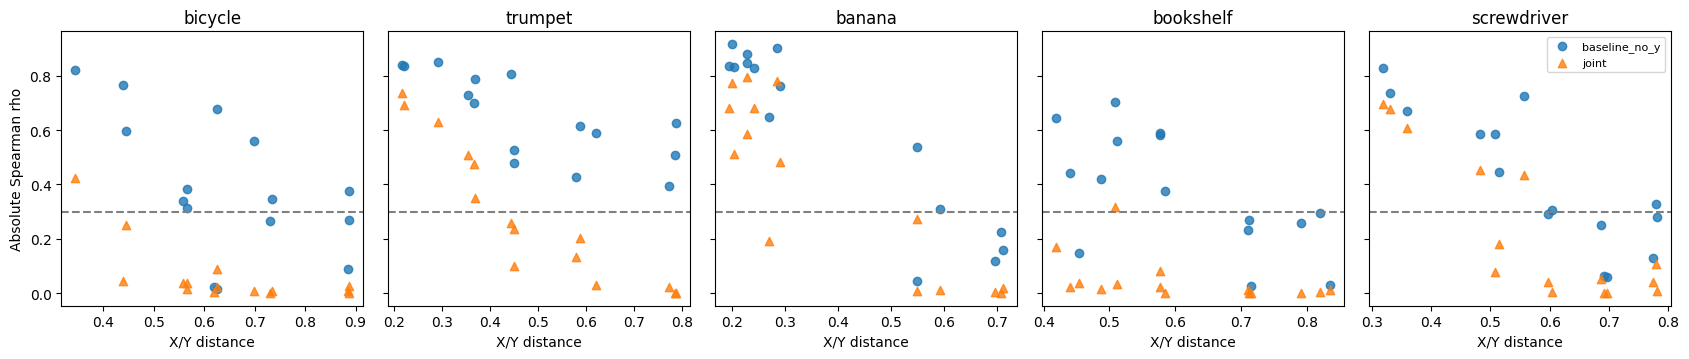

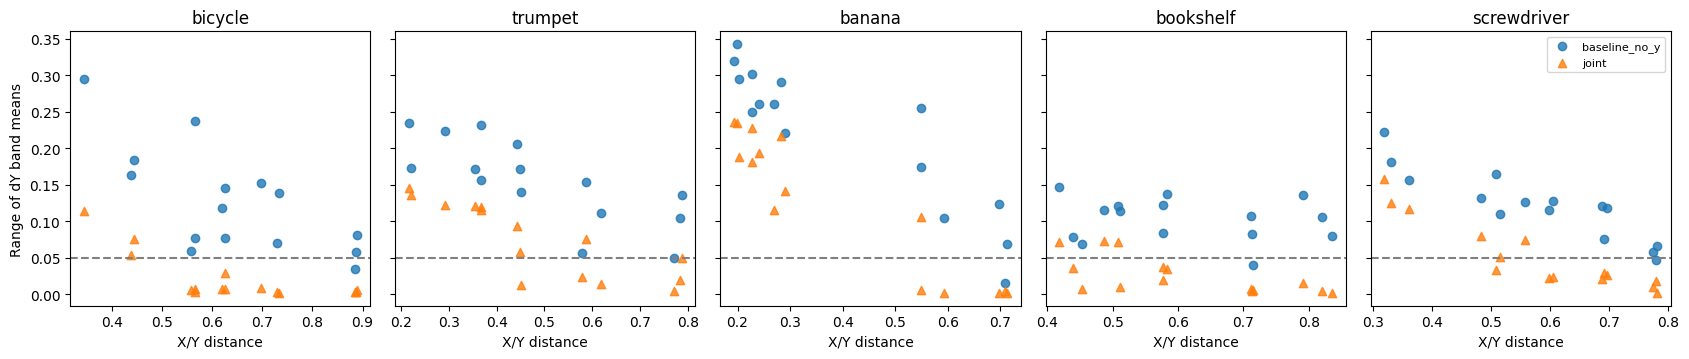

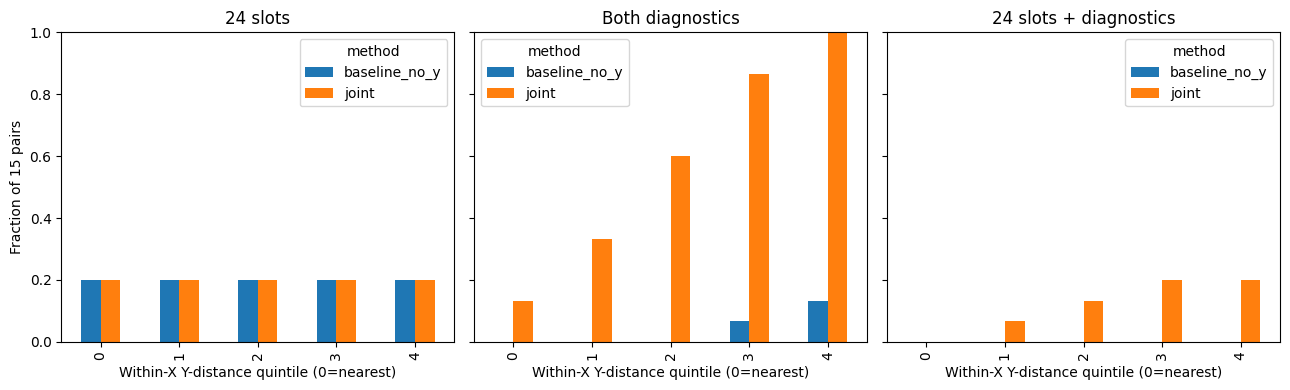

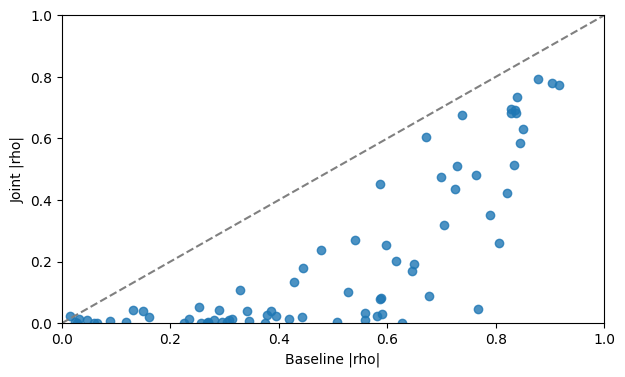

# Experiment D — exploratory results

Primary pairs: 75; original anchors: 5. No generation API or embedding inference.
Fixed setting C, 24 slots, exact maximum cardinality, approximate joint search (3 seeds × 1200 steps). No missing slot hidden; diagnostic success on partial sets is not full success.

- known_audit_fail_excluded / baseline_no_y: n=75, complete=15, diagnostic=3, full=0, mean |rho|=0.4836, mean spread=0.1447
- known_audit_fail_excluded / joint: n=75, complete=15, diagnostic=44, full=9, mean |rho|=0.2041, mean spread=0.0596
- old_quality_no_y_name / baseline_no_y: n=75, complete=15, diagnostic=3, full=0, mean |rho|=0.4839, mean spread=0.1447
- old_quality_no_y_name / joint: n=75, complete=15, diagnostic=44, full=9, mean |rho|=0.2039, mean spread=0.0596

Among the 25 pairs measured in C, 4 meet D full and C exploratory screen.

## Limitations
B cues were generated/audited relative to original Y; new-Y semantic audit covers only a sample, and unaudited cues are not certifi

In [7]:
# Figures, final provenance, and summary. No generated API usage.
def figsave(name,fig):
    buf=io.BytesIO();fig.savefig(buf,format='png',dpi=150,bbox_inches='tight')
    n='figures/'+name+'.png';put(n,buf.getvalue());outputs.append(n);plt.show();plt.close(fig)
main=p[p.pool==CFG['primary_pool']]
for outcome,ylabel,threshold in [('abs_rho','Absolute Spearman rho',CFG['rho_target']),('spread','Range of dY band means',CFG['spread_target'])]:
    fig,axs=plt.subplots(1,5,figsize=(17,3.7),sharey=True)
    for ax,(pid,g) in zip(axs,main.groupby('pair')):
        for method,mark in [('baseline_no_y','o'),('joint','^')]:
            z=g[g.method==method];ax.scatter(z.distance_xy,z[outcome],marker=mark,label=method,alpha=.8)
        ax.axhline(threshold,ls='--',color='gray');ax.set_xlabel('X/Y distance');ax.set_title(g.x.iloc[0])
    axs[0].set_ylabel(ylabel);axs[-1].legend(fontsize=8);fig.tight_layout();figsave(outcome,fig)
fig,axs=plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,k,title in zip(axs,['complete','diagnostic_target_met','full_target_met'],['24 slots','Both diagnostics','24 slots + diagnostics']):
    h=main.groupby(['distance_band','method'])[k].mean().unstack()
    h.plot.bar(ax=ax);ax.set_title(title);ax.set_xlabel('Within-X Y-distance quintile (0=nearest)');ax.set_ylim(0,1)
axs[0].set_ylabel('Fraction of 15 pairs');fig.tight_layout();figsave('pass_by_distance_band',fig)
fig,ax=plt.subplots(figsize=(7,4))
v=main.pivot(index='candidate_id',columns='method',values='abs_rho').dropna()
ax.scatter(v.baseline_no_y,v.joint,alpha=.8);ax.plot([0,1],[0,1],ls='--',color='gray');ax.set(xlabel='Baseline |rho|',ylabel='Joint |rho|',xlim=(0,1),ylim=(0,1));figsave('paired_rho',fig)
report=['# Experiment D — exploratory results','',f"Primary pairs: {int(pairs.primary_selected.sum())}; original anchors: {int(pairs.original_y.sum())}. No generation API or embedding inference.",'Fixed setting C, 24 slots, exact maximum cardinality, approximate joint search (3 seeds × 1200 steps). No missing slot hidden; diagnostic success on partial sets is not full success.','']
for row in aggregate(p,['pool','method']).itertuples():
    report.append(f"- {row.pool} / {row.method}: n={row.n}, complete={row.complete_n}, diagnostic={row.diagnostic_n}, full={row.full_n}, mean |rho|={row.mean_abs_rho:.4f}, mean spread={row.mean_spread:.4f}")
report+=['',f"Among the {int(j.C_measured.sum())} pairs measured in C, {int((j.D_and_C_exploratory==1).sum())} meet D full and C exploratory screen.",'','## Limitations','B cues were generated/audited relative to original Y; new-Y semantic audit covers only a sample, and unaudited cues are not certified. Full success is a numeric/structural diagnostic, not formal stimulus adoption. Only five X families; shared cue pools and category/token confounding. Approximate search failure is not proof of infeasibility. Structural shortage is exact for the frozen candidate pool only. C uses 16 train/8 eval texts, not formal confirmation. No suppression outcomes were used. No distance cutoff is established by these exploratory results.']
put('analysis_summary.md',('\n'.join(report)+'\n').encode());outputs.append('analysis_summary.md')
manifest={'status':'complete_exploratory','config_sha256':sha(dump(config)),'source_B_ref':CFG['B_ref'],'source_C_ref':CFG['C_ref'],'C_input_sha256':{'manifest':sha(cmraw),'probe_l24_scores':sha(cr)},'api_generation_calls':0,'n_primary':75,'n_anchors':5,'versions':{k:im.version(k) for k in ['numpy','pandas','scipy','matplotlib']},'python':platform.python_version(),'files':{n:sha(get(n)) for n in outputs},'checkpoints':{pid:sha(get('checkpoints/'+pid+'.zip')) for pid in sorted(pairs.pair.unique())}}
put('manifest.json',dump(manifest))
print('\n'.join(report))
print('https://github.com/'+REPO+'/tree/'+BRANCH+'/'+DEST)
